# Green Growth — Phase 1: Download the data

<div dir="rtl">

هدف این مرحله: دریافت دادهٔ خام و نگهداری آن در پوشهٔ مشخص. هنوز داده را به DataFrame تبدیل نمی‌کنیم.

فایل Notebook را در ریشهٔ پروژه، کنار README.md قرار بده. در VS Code همان پوشهٔ پروژه را باز کن و سلول‌ها را از بالا به پایین اجرا کن. برای این مرحله فقط کتابخانه‌های استاندارد Python لازم است؛ محیط اجرای Notebook به Jupyter و ipykernel نیاز دارد.

</div>

**Source:** [Our World in Data CO₂ dataset](https://github.com/owid/co2-data). We use a fixed repository revision for reproducibility, not a continuously changing latest URL. The repository reports that this export is no longer updated. Keep this snapshot and its codebook together. GDP, population and CO₂ have different coverage; we will inspect missing values and units before analysis. No country or year has been selected yet.

<div dir="rtl">

### ۱. ابزارهای لازم

`Path` مسیر فایل‌ها را می‌سازد. `urlopen` فایل اینترنتی را دریافت می‌کند. ابزارهای دیگر برای کپی فایل، ثبت منبع و بررسی صحت دانلود هستند. این بخش فقط زیرساخت دریافت داده است؛ منطق تحلیل را در مراحل بعد با تمرین خودت می‌نویسیم.

</div>

In [1]:
from pathlib import Path
from urllib.request import urlopen
import shutil
import csv
import hashlib
import json
from datetime import datetime, timezone

<div dir="rtl">

### ۲. مسیر پروژه و پوشهٔ داده

Notebook متغیر `__file__` ندارد. به همین دلیل از پوشهٔ کاری Kernel شروع می‌کنیم و ریشهٔ پروژه را با وجود فایل README پیدا می‌کنیم. این روش از ریشه یا زیرپوشه‌های پروژه کار می‌کند؛ اگر Kernel بیرون پروژه اجرا شود، پیام خطای روشن می‌دهد. هیچ مسیر شخصی ویندوزی در کد نیست.

`parents=True` پوشه‌های میانی و `exist_ok=True` امکان اجرای دوباره را فراهم می‌کند.

</div>

In [2]:
working_directory = Path.cwd().resolve()
project_root = next(
    (folder for folder in (working_directory, *working_directory.parents)
     if (folder / "README.md").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open the project folder containing README.md and restart the kernel.")

raw_directory = project_root / "data" / "raw"
raw_directory.mkdir(parents=True, exist_ok=True)
print("Data folder:", raw_directory)

Data folder: C:\Users\esmae\Desktop\ITALY\Milan\University\Semester 1\GitHub-Projects\unimi-python-project-2026\data\raw


<div dir="rtl">

### ۳. منبع ثابت

دو فایل می‌گیریم: جدول اصلی و Codebook برای تعریف ستون‌ها و واحدها. لینک‌ها به یک Commit مشخص اشاره دارند تا داده در سیستم دیگر تغییر نکند. فایل اصلی برای بررسی اولیهٔ رشد اقتصادی، CO₂ و جمعیت مناسب است؛ انتخاب نهایی شاخص‌ها پس از خواندن Codebook انجام می‌شود. برای بررسی دقیق ترکیب منابع انرژی، بعداً ممکن است مجموعهٔ انرژی جداگانه لازم شود.

</div>

In [3]:
source_revision = "22d9a01321ddec951b36f2bfc66e05dc6ad50ad8"
base_url = f"https://raw.githubusercontent.com/owid/co2-data/{source_revision}"
source_files = ["owid-co2-data.csv", "owid-co2-codebook.csv"]

<div dir="rtl">

### ۴. دانلود و کنترل فایل

هر فایل ابتدا با پسوند موقت دریافت می‌شود. پس از بررسی سرستون‌ها، فایل کامل جایگزین می‌شود؛ خطای شبکه فایل نیمه‌کاره را به جای دادهٔ معتبر باقی نمی‌گذارد. اجرای مجدد فایل‌های موجود را نیز بررسی می‌کند و دوباره دانلود نمی‌کند. اندازه، زمان دریافت اولیه و SHA-256 در فایل منابع ثبت می‌شود. SHA-256 برای مقایسهٔ نسخه‌هاست و به تنهایی صحت علمی داده را ثابت نمی‌کند.

</div>

In [4]:
manifest_path = raw_directory / "sources.json"
previous_records = {}
if manifest_path.exists():
    previous_records = {
        record["filename"]: record
        for record in json.loads(manifest_path.read_text(encoding="utf-8"))
    }

records = []
for filename in source_files:
    destination = raw_directory / filename
    temporary = destination.with_suffix(".csv.part")
    source_url = f"{base_url}/{filename}"
    downloaded = False
    try:
        if not destination.exists():
            with urlopen(source_url, timeout=60) as response:
                with temporary.open("wb") as output:
                    shutil.copyfileobj(response, output)
            candidate = temporary
            downloaded = True
        else:
            candidate = destination

        with candidate.open(encoding="utf-8-sig", newline="") as input_file:
            reader = csv.reader(input_file)
            header = next(reader)
            first_row = next(reader)
        required_columns = (
            {"country", "year", "co2", "gdp", "population"}
            if filename == "owid-co2-data.csv"
            else {"column", "description", "unit"}
        )
        if not required_columns.issubset(header) or len(first_row) != len(header):
            raise ValueError(f"Unexpected CSV structure: {filename}")

        digest = hashlib.sha256(candidate.read_bytes()).hexdigest()
        previous = previous_records.get(filename)
        if not downloaded and previous and digest != previous["sha256"]:
            raise ValueError(f"Local file changed: {filename}. Restore the original raw file.")
        if downloaded:
            temporary.replace(destination)
        retrieved_at = (
            datetime.now(timezone.utc).isoformat() if downloaded
            else previous.get("retrieved_at_utc") if previous else None
        )
        records.append({
            "filename": filename,
            "url": source_url,
            "revision": source_revision,
            "retrieved_at_utc": retrieved_at,
            "bytes": destination.stat().st_size,
            "sha256": digest,
        })
        print(f"{'Downloaded' if downloaded else 'Verified existing'}: {filename}")
    except Exception:
        temporary.unlink(missing_ok=True)
        raise

manifest_path.write_text(json.dumps(records, indent=2), encoding="utf-8")
print("Phase 1 complete. Source metadata saved.")

Verified existing: owid-co2-data.csv
Verified existing: owid-co2-codebook.csv
Phase 1 complete. Source metadata saved.


<div dir="rtl">

### ۵. بررسی نتیجه

فهرست زیر باید شامل CSV اصلی، Codebook و فایل ثبت منبع باشد. در این مرحله فایل خام را تغییر نمی‌دهیم. هیچ DataFrame ساخته نشده است.

</div>

In [5]:
for file_path in sorted(raw_directory.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")

owid-co2-codebook.csv: 65,125 bytes
owid-co2-data.csv: 15,242,657 bytes
sources.json: 806 bytes


<div dir="rtl">

### توقف آموزشی — قبل از pandas

۱. تفاوت لینک دانلود با مسیر ذخیره چیست؟

۲. چرا از `Path` و مسیر نسبی به ریشهٔ پروژه استفاده کردیم؟

۳. اگر سلول دانلود را دوباره اجرا کنی چه اتفاقی می‌افتد؟

۴. چرا Codebook را هم ذخیره کرده‌ایم؟

۵. چرا دادهٔ گمشده را نمی‌توانیم بدون بررسی صفر در نظر بگیریم؟

پاسخ‌هایت را توضیح بده؛ بعد به مرحلهٔ بعد می‌رویم.

### فاز بعد: خواندن داده با pandas

سلول‌های کد زیر عمداً خالی هستند. در مرحلهٔ بعد به ترتیب `pandas` را وارد می‌کنیم، فایل محلی را با `read_csv` می‌خوانیم، سپس `head`، `shape`، نوع ستون‌ها و داده‌های گمشده را بررسی می‌کنیم.

</div>

In [6]:
import pandas as pd

In [7]:
data_path = raw_directory / "owid-co2-data.csv"
df = pd.read_csv(data_path)

df.head()

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.shape

(56269, 79)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56269 entries, 0 to 56268
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    56269 non-null  str    
 1   year                                       56269 non-null  int64  
 2   iso_code                                   48306 non-null  str    
 3   population                                 44124 non-null  float64
 4   gdp                                        15367 non-null  float64
 5   cement_co2                                 38425 non-null  float64
 6   cement_co2_per_capita                      31816 non-null  float64
 7   co2                                        30219 non-null  float64
 8   co2_growth_abs                             28038 non-null  float64
 9   co2_growth_prct                            26839 non-null  float64
 10  co2_including_luc                

In [10]:
df[["country", "year", "population", "gdp", "co2"]].head(10)

,country,year,population,gdp,co2
0,Afghanistan,1750,2802560.0,NaN,NaN
1,Afghanistan,1751,NaN,NaN,NaN
2,Afghanistan,1752,NaN,NaN,NaN
3,Afghanistan,1753,NaN,NaN,NaN
4,Afghanistan,1754,NaN,NaN,NaN
5,Afghanistan,1755,NaN,NaN,NaN
6,Afghanistan,1756,NaN,NaN,NaN
7,Afghanistan,1757,NaN,NaN,NaN
8,Afghanistan,1758,NaN,NaN,NaN
9,Afghanistan,1759,NaN,NaN,NaN


In [11]:
print("First year:", df["year"].min())
print("Last year:", df["year"].max())

First year: 1750
Last year: 2025


In [12]:
duplicate_count = df.duplicated(subset=["country", "year"]).sum()

print("Duplicate country-year rows:", duplicate_count)

Duplicate country-year rows: 0


In [13]:
main_columns = ["country", "year", "population", "gdp", "co2"]

df[main_columns].isna().sum()

country           0
year              0
population    12145
gdp           40902
co2           26050
dtype: int64

In [14]:
codebook_path = raw_directory / "owid-co2-codebook.csv"
codebook = pd.read_csv(codebook_path)

codebook.loc[
    codebook["column"].isin(["population", "gdp", "co2"]),
    ["column", "description", "unit"]
]

,column,description,unit
3,population,"Population by country, available from 10,000 B...",people
4,gdp,Total economic output of a country or region p...,international-$ in 2011 prices ($)
7,co2,Annual total emissions of carbon dioxide (CO₂)...,million tonnes (Mt)


In [15]:
indicator_details = codebook.loc[
    codebook["column"].isin(["population", "gdp", "co2"]),
    ["column", "description", "unit"]
]

print(indicator_details.to_string(index=False))

    column                                                                                                                                   description                               unit
population                                 Population by country, available from 10,000 BCE to 2100, based on data and estimates from different sources.                             people
       gdp Total economic output of a country or region per year. This data is adjusted for inflation and differences in living costs between countries. international-$ in 2011 prices ($)
       co2                                        Annual total emissions of carbon dioxide (CO₂), excluding land-use change, measured in million tonnes.                million tonnes (Mt)


In [16]:
complete_rows = df.dropna(subset=["gdp", "co2"])

coverage_by_year = complete_rows.groupby("year").size()

print(coverage_by_year.tail(15))

year
2008    164
2009    164
2010    165
2011    164
2012    164
2013    164
2014    164
2015    165
2016    165
2017    165
2018    165
2019    165
2020    165
2021    165
2022    165
dtype: int64


In [17]:
print(coverage_by_year.loc[1990:2000])

year
1990    164
1991    163
1992    163
1993    164
1994    164
1995    164
1996    164
1997    164
1998    164
1999    164
2000    165
dtype: int64


In [18]:
entities = df[["country", "iso_code"]].drop_duplicates()

print(entities.to_string(index=False))

                                 country iso_code
                             Afghanistan      AFG
                                  Africa      NaN
                            Africa (GCP)      NaN
                                 Albania      ALB
                                 Algeria      DZA
                                 Andorra      AND
                                  Angola      AGO
                                Anguilla      AIA
                              Antarctica      ATA
                     Antigua and Barbuda      ATG
                               Argentina      ARG
                                 Armenia      ARM
                                   Aruba      ABW
                                    Asia      NaN
                              Asia (GCP)      NaN
            Asia (excl. China and India)      NaN
                               Australia      AUS
                                 Austria      AUT
                              Azerbaijan      AZE


In [19]:
entities_without_code = entities.loc[
    entities["iso_code"].isna(),
    ["country", "iso_code"]
]

print(entities_without_code.to_string(index=False))

                                 country iso_code
                                  Africa      NaN
                            Africa (GCP)      NaN
                                    Asia      NaN
                              Asia (GCP)      NaN
            Asia (excl. China and India)      NaN
                   Central America (GCP)      NaN
                                  Europe      NaN
                            Europe (GCP)      NaN
                    Europe (excl. EU-27)      NaN
                    Europe (excl. EU-28)      NaN
                     European Union (27)      NaN
                     European Union (28)      NaN
                   High-income countries      NaN
                  International aviation      NaN
                  International shipping      NaN
                                  Kosovo      NaN
                       Kuwaiti Oil Fires      NaN
                 Kuwaiti Oil Fires (GCP)      NaN
Least developed countries (Jones et al.)      NaN


In [20]:
selected_countries = [
    "Italy",
    "Germany",
    "United States",
    "China",
    "India",
]

selected_df = df.loc[
    df["country"].isin(selected_countries)
    & df["year"].between(1990, 2022),
    main_columns
].copy()

print("Selected shape:", selected_df.shape)
print("Countries:", selected_df["country"].unique())

Selected shape: (165, 5)
Countries: <StringArray>
['China', 'Germany', 'India', 'Italy', 'United States']
Length: 5, dtype: str


In [21]:
selected_df.isna().sum()

country       0
year          0
population    0
gdp           0
co2           0
dtype: int64

In [22]:
print("GDP <= 0:", (selected_df["gdp"] <= 0).sum())
print("Population <= 0:", (selected_df["population"] <= 0).sum())
print("CO2 < 0:", (selected_df["co2"] < 0).sum())

GDP <= 0: 0
Population <= 0: 0
CO2 < 0: 0


In [23]:
selected_df = selected_df.sort_values(
    ["country", "year"]
).reset_index(drop=True)

selected_df.head()

,country,year,population,gdp,co2
0,China,1990,1.153583e+09,3.385122e+12,2488.302
1,China,1991,1.170789e+09,3.508948e+12,2624.119
2,China,1992,1.184574e+09,3.755038e+12,2736.215
3,China,1993,1.197309e+09,4.126169e+12,2919.553
4,China,1994,1.209003e+09,4.438753e+12,3101.516


In [24]:
endpoint_data = selected_df.loc[
    selected_df["year"].isin([1990, 2022]),
    ["country", "year", "gdp", "co2"]
].copy()

endpoint_data

,country,year,gdp,co2
0,China,1990,3.385122e+12,2488.302
32,China,2022,2.696602e+13,11695.013
33,Germany,1990,2.015547e+12,1054.796
65,Germany,2022,3.909613e+12,670.017
66,India,1990,1.750993e+12,584.082
98,India,2022,1.047625e+13,2821.410
99,Italy,1990,1.475485e+12,438.208
131,Italy,2022,2.136009e+12,336.796
132,United States,1990,9.250378e+12,5129.972
164,United States,2022,1.949317e+13,5065.986


In [25]:
start_data = endpoint_data.loc[
    endpoint_data["year"] == 1990
].set_index("country")

end_data = endpoint_data.loc[
    endpoint_data["year"] == 2022
].set_index("country")

start_data

,year,gdp,co2
country,,,
China,1990,3.385122e+12,2488.302
Germany,1990,2.015547e+12,1054.796
India,1990,1.750993e+12,584.082
Italy,1990,1.475485e+12,438.208
United States,1990,9.250378e+12,5129.972


In [26]:
gdp_change_pct = (
    (end_data["gdp"] - start_data["gdp"])
    / start_data["gdp"]
    * 100
)

gdp_change_pct

country
China            696.604070
Germany           93.972742
India            498.303285
Italy             44.766561
United States    110.728373
Name: gdp, dtype: float64

In [27]:
co2_change_pct = (
    (end_data["co2"] - start_data["co2"])
    / start_data["co2"]
    * 100
)

co2_change_pct

country
China            369.999743
Germany          -36.478997
India            383.050325
Italy            -23.142435
United States     -1.247297
Name: co2, dtype: float64

In [28]:
growth_summary = pd.DataFrame({
    "gdp_change_pct": gdp_change_pct,
    "co2_change_pct": co2_change_pct,
})

growth_summary.round(2)

,gdp_change_pct,co2_change_pct
country,,
China,696.60,370.00
Germany,93.97,-36.48
India,498.30,383.05
Italy,44.77,-23.14
United States,110.73,-1.25


In [29]:
growth_summary["gdp_up_co2_down"] = (
    (growth_summary["gdp_change_pct"] > 0)
    & (growth_summary["co2_change_pct"] < 0)
)

growth_summary.round(2)

,gdp_change_pct,co2_change_pct,gdp_up_co2_down
country,,,
China,696.60,370.00,False
Germany,93.97,-36.48,True
India,498.30,383.05,False
Italy,44.77,-23.14,True
United States,110.73,-1.25,True


In [30]:
baseline_gdp = selected_df["country"].map(start_data["gdp"])

baseline_gdp.head()

0    3.385122e+12
1    3.385122e+12
2    3.385122e+12
3    3.385122e+12
4    3.385122e+12
Name: country, dtype: float64

In [31]:
selected_df["gdp_index"] = (
    selected_df["gdp"] / baseline_gdp * 100
)

selected_df[["country", "year", "gdp_index"]].head()

,country,year,gdp_index
0,China,1990,100.000000
1,China,1991,103.657958
2,China,1992,110.927703
3,China,1993,121.891312
4,China,1994,131.125375


In [32]:
baseline_co2 = selected_df["country"].map(start_data["co2"])

selected_df["co2_index"] = (
    selected_df["co2"] / baseline_co2 * 100
)

selected_df[["country", "year", "gdp_index", "co2_index"]].head()

,country,year,gdp_index,co2_index
0,China,1990,100.000000,100.000000
1,China,1991,103.657958,105.458220
2,China,1992,110.927703,109.963140
3,China,1993,121.891312,117.331136
4,China,1994,131.125375,124.643874


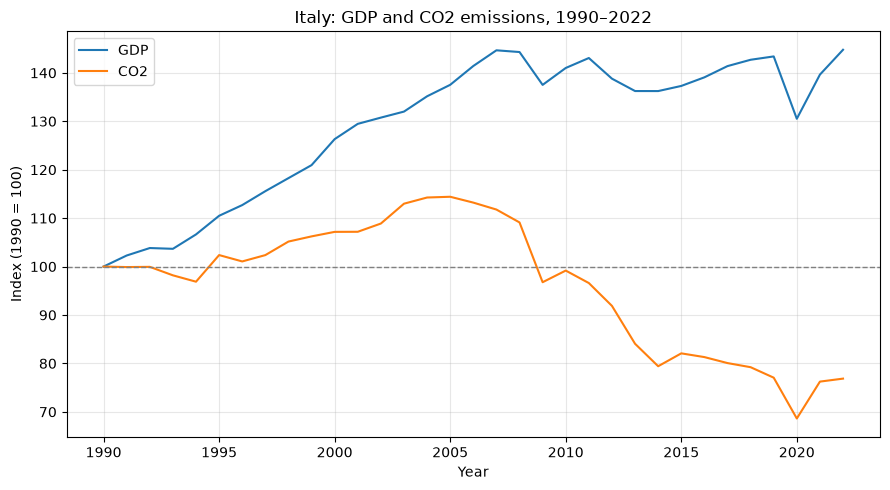

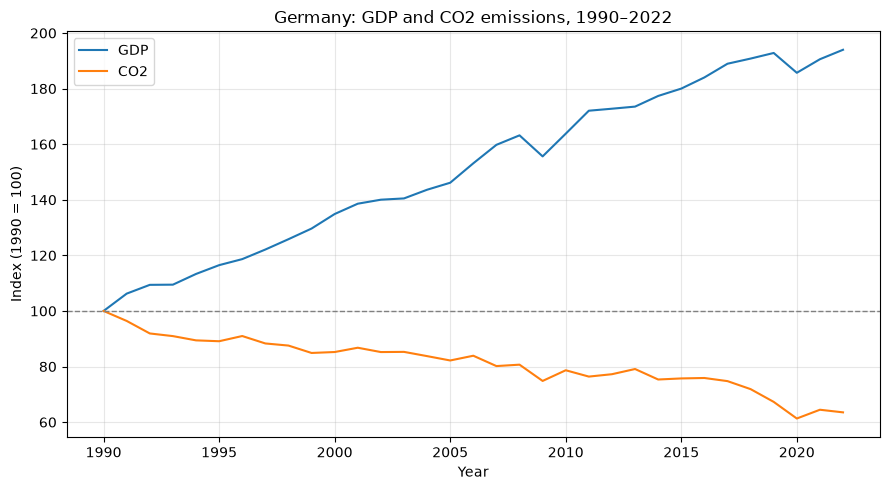

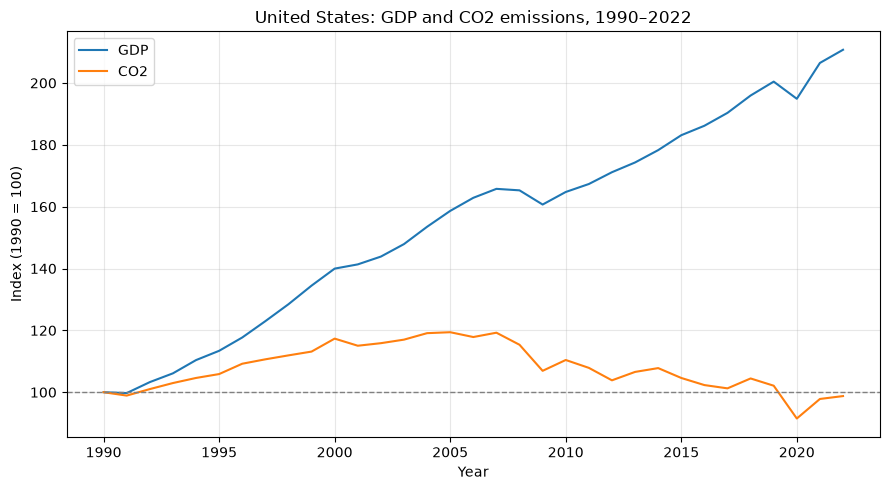

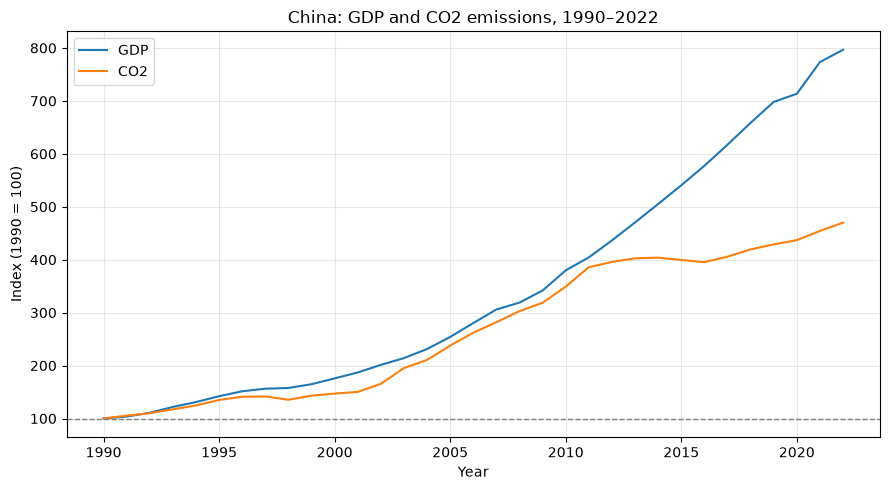

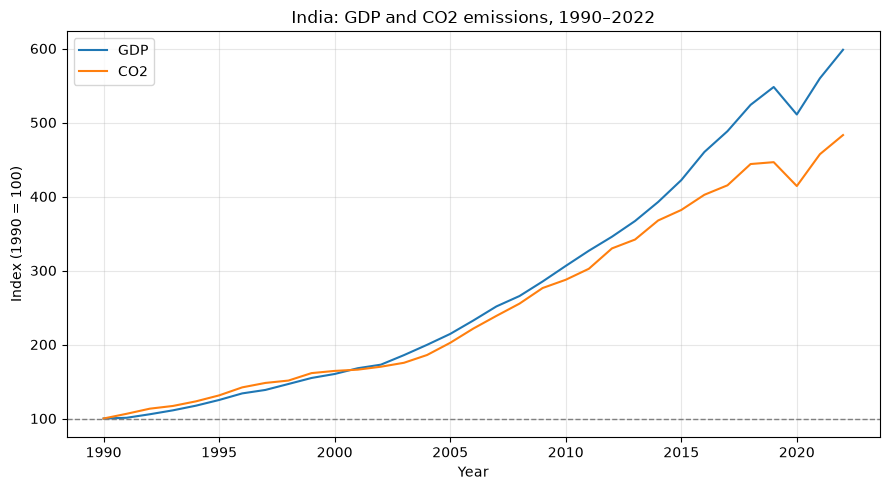

In [33]:
import matplotlib.pyplot as plt

figures_directory = project_root / "outputs" / "figures"
figures_directory.mkdir(parents=True, exist_ok=True)

for country in selected_countries:
    country_data = selected_df.loc[
        selected_df["country"] == country
    ]

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(country_data["year"], country_data["gdp_index"], label="GDP")
    ax.plot(country_data["year"], country_data["co2_index"], label="CO2")

    ax.axhline(100, color="gray", linestyle="--", linewidth=1)

    ax.set_title(f"{country}: GDP and CO2 emissions, 1990–2022")
    ax.set_xlabel("Year")
    ax.set_ylabel("Index (1990 = 100)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    filename = country.lower().replace(" ", "_") + "_gdp_co2_index.png"
    fig.savefig(figures_directory / filename, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [34]:
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])

for package in ["pandas", "numpy", "matplotlib", "ipykernel"]:
    print(f"{package}: {version(package)}")

Python: 3.14.7
pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2
ipykernel: 7.4.0
